# Extension — Deep MLPs (5–10 hidden layers) with PyTorch

The same two tasks (Iris, Breast Cancer) with the **same** stratified 70:30 / 80:20 splits and scaling as
in Q1/Q2, but built with a library (PyTorch) and with much deeper networks.

| Item | Setting |
|---|---|
| Hidden layers | 5, 7, 10 (32 neurons each, ReLU) |
| Output | Iris: 3 outputs + `CrossEntropyLoss` (= softmax + categorical cross-entropy) · Cancer: 1 output + `BCEWithLogitsLoss` (= sigmoid + binary cross-entropy) |
| Optimiser | Adam, learning rate 0.001, full batch, 300 epochs |
| Init | PyTorch default, seed 42 |

In [1]:
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from IPython.display import display

import helpers as H

H.set_style()
torch.set_default_dtype(torch.float64)
pd.set_option("display.precision", 4)
OUT_DIR = "results/q3"
os.makedirs(OUT_DIR, exist_ok=True)
print("PyTorch", torch.__version__)

DATASETS = {"iris": H.load_data("iris"), "breast_cancer": H.load_data("breast_cancer")}
SPLITS = [0.30, 0.20]
DEPTHS = [5, 7, 10]

PyTorch 2.9.1+cpu


## 1. Model and training

In [2]:
def deep_mlp(n_in, n_out, depth, width=32):
    layers, d = [], n_in
    for _ in range(depth):
        layers += [nn.Linear(d, width), nn.ReLU()]
        d = width
    layers.append(nn.Linear(d, n_out))
    return nn.Sequential(*layers)


def train_torch(dataset, depth, test_size, lr=1e-3, epochs=300, seed=42, width=32):
    X, y, _, class_names = DATASETS[dataset]
    X_tr, X_te, y_tr, y_te, _ = H.split_and_scale(X, y, test_size, seed)
    binary = len(class_names) == 2
    torch.manual_seed(seed)
    net = deep_mlp(X.shape[1], 1 if binary else len(class_names), depth, width)
    opt = torch.optim.Adam(net.parameters(), lr=lr)
    loss_fn = nn.BCEWithLogitsLoss() if binary else nn.CrossEntropyLoss()
    to_t = lambda v: torch.tensor(v, dtype=torch.float64).unsqueeze(1) if binary else torch.tensor(v).long()
    Xt, Xv, yt, yv = torch.tensor(X_tr), torch.tensor(X_te), to_t(y_tr), to_t(y_te)

    hist = {"train_loss": [], "test_loss": []}
    for _ in range(epochs):
        opt.zero_grad()
        loss = loss_fn(net(Xt), yt); loss.backward(); opt.step()
        with torch.no_grad():
            hist["train_loss"].append(loss.item()); hist["test_loss"].append(loss_fn(net(Xv), yv).item())

    with torch.no_grad():
        predict = (lambda o: (o.ravel() > 0).long().numpy()) if binary else (lambda o: o.argmax(1).numpy())
        p_tr, p_te = predict(net(Xt)), predict(net(Xv))
    return {"dataset": dataset, "arch": f"{depth}×{width}", "split": H.split_name(test_size),
            "net": net, "history": hist, "n_train": len(y_tr), "n_test": len(y_te),
            "train": H.evaluate(y_tr, p_tr, binary), "test": H.evaluate(y_te, p_te, binary)}


class _Wrap:
    """Lets the plotting/table helpers (written for the scratch MLP) accept PyTorch results."""
    def __init__(self, r):
        self.history = r["history"]
        self._n = sum(p.numel() for p in r["net"].parameters())
    def n_params(self):
        return self._n

def as_helper_results(rs):
    return [{**r, "model": _Wrap(r)} for r in rs]

torch_results = {}
t0 = time.time()
for ds in DATASETS:
    torch_results[ds] = []
    for ts in SPLITS:
        for d in DEPTHS:
            r = train_torch(ds, d, ts)
            torch_results[ds].append(r)
            print(f"{ds:>13} | {d:2d} hidden layers | {r['split']} | final loss {r['history']['train_loss'][-1]:.5f} "
                  f"| test acc {r['test']['accuracy']:.4f}")
print(f"done in {time.time() - t0:.1f}s")

         iris |  5 hidden layers | 70:30 | final loss 0.00028 | test acc 0.9333


         iris |  7 hidden layers | 70:30 | final loss 0.00007 | test acc 0.9111


         iris | 10 hidden layers | 70:30 | final loss 0.00007 | test acc 0.9111


         iris |  5 hidden layers | 80:20 | final loss 0.00083 | test acc 0.9667


         iris |  7 hidden layers | 80:20 | final loss 0.00021 | test acc 0.9667


         iris | 10 hidden layers | 80:20 | final loss 0.00009 | test acc 0.9667


... (2 outputs left out)

breast_cancer | 10 hidden layers | 70:30 | final loss 0.00002 | test acc 0.9708


breast_cancer |  5 hidden layers | 80:20 | final loss 0.00022 | test acc 0.9737


breast_cancer |  7 hidden layers | 80:20 | final loss 0.00003 | test acc 0.9825


breast_cancer | 10 hidden layers | 80:20 | final loss 0.00002 | test acc 0.9825
done in 45.5s


## 2. Performance metrics (test set)

In [3]:
for ds, rs in torch_results.items():
    t = H.metrics_table(as_helper_results(rs)).rename(columns={"Architecture": "Hidden layers × width"})
    t.to_csv(f"{OUT_DIR}/{ds}_torch_metrics.csv")
    print(ds); display(H.format_table(t))

iris


,Hidden layers × width,Split,Train / Test,Params,Final train loss,Train acc,Test acc,Precision,Recall,F1-score
Exp,,,,,,,,,,
1,5×32,70:30,105 / 45,4483,0.0003,1.0000,0.9333,0.9345,0.9333,0.9333
2,7×32,70:30,105 / 45,6595,0.0001,1.0000,0.9111,0.9155,0.9111,0.9107
3,10×32,70:30,105 / 45,9763,0.0001,1.0000,0.9111,0.9155,0.9111,0.9107
4,5×32,80:20,120 / 30,4483,0.0008,1.0000,0.9667,0.9697,0.9667,0.9666
5,7×32,80:20,120 / 30,6595,0.0002,1.0000,0.9667,0.9697,0.9667,0.9666
6,10×32,80:20,120 / 30,9763,0.0001,1.0000,0.9667,0.9697,0.9667,0.9666


breast_cancer


,Hidden layers × width,Split,Train / Test,Params,Final train loss,Train acc,Test acc,Precision,Recall,F1-score
Exp,,,,,,,,,,
1,5×32,70:30,398 / 171,5249,0.0002,1.0000,0.9766,0.9839,0.9531,0.9683
2,7×32,70:30,398 / 171,7361,0.0000,1.0000,0.9649,0.9677,0.9375,0.9524
3,10×32,70:30,398 / 171,10529,0.0000,1.0000,0.9708,0.9683,0.9531,0.9606
4,5×32,80:20,455 / 114,5249,0.0002,1.0000,0.9737,0.9756,0.9524,0.9639
5,7×32,80:20,455 / 114,7361,0.0000,1.0000,0.9825,0.9762,0.9762,0.9762
6,10×32,80:20,455 / 114,10529,0.0000,1.0000,0.9825,0.9762,0.9762,0.9762


## 3. Confusion matrices and loss curves

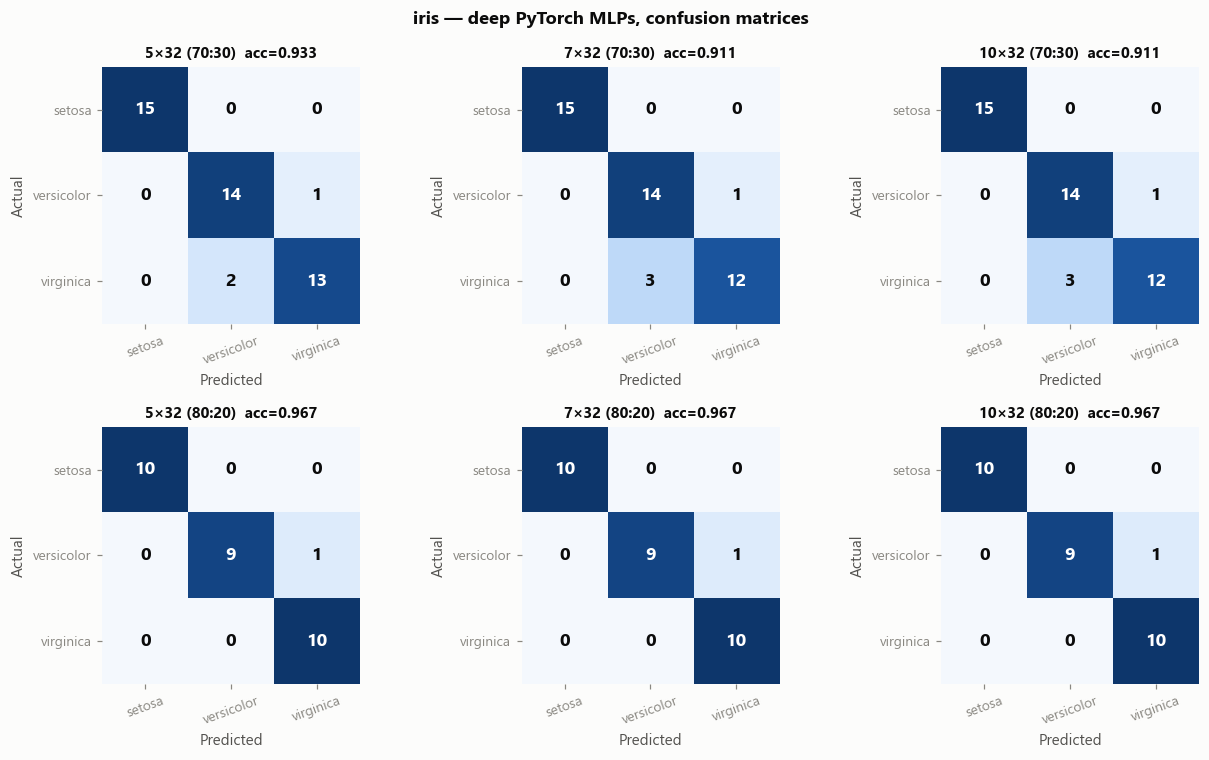

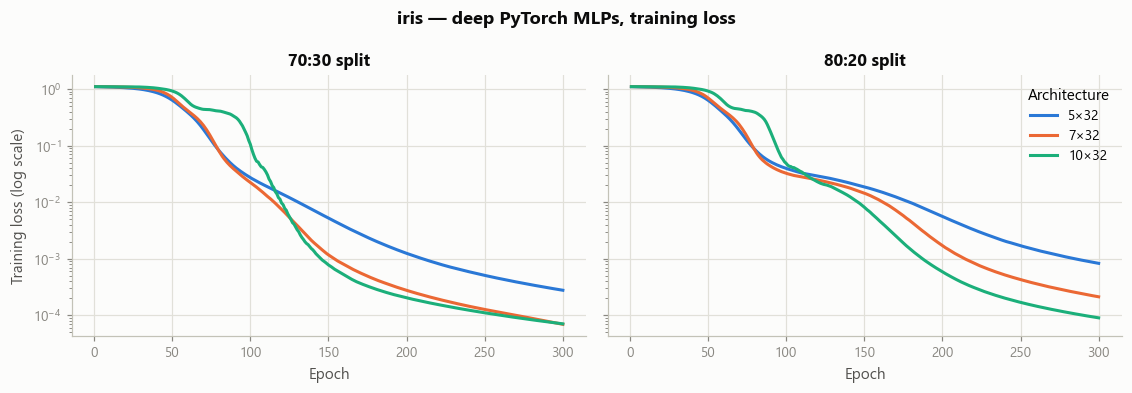

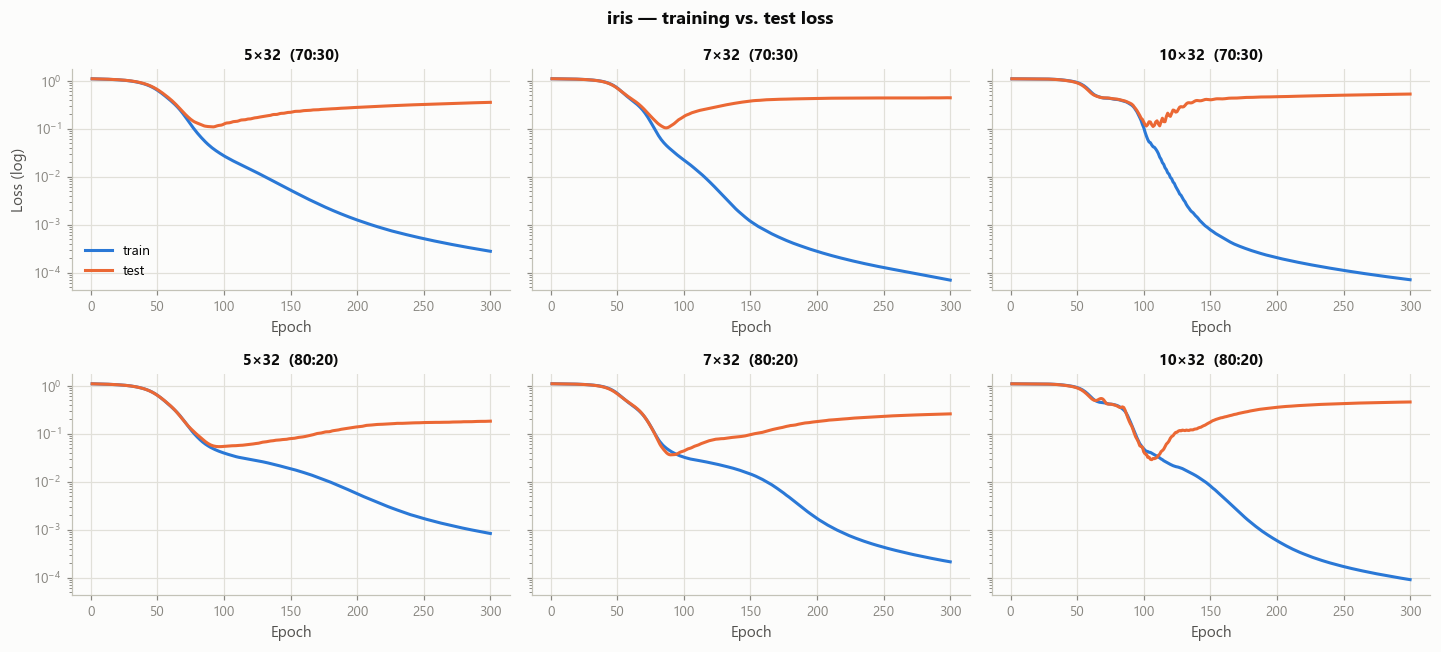

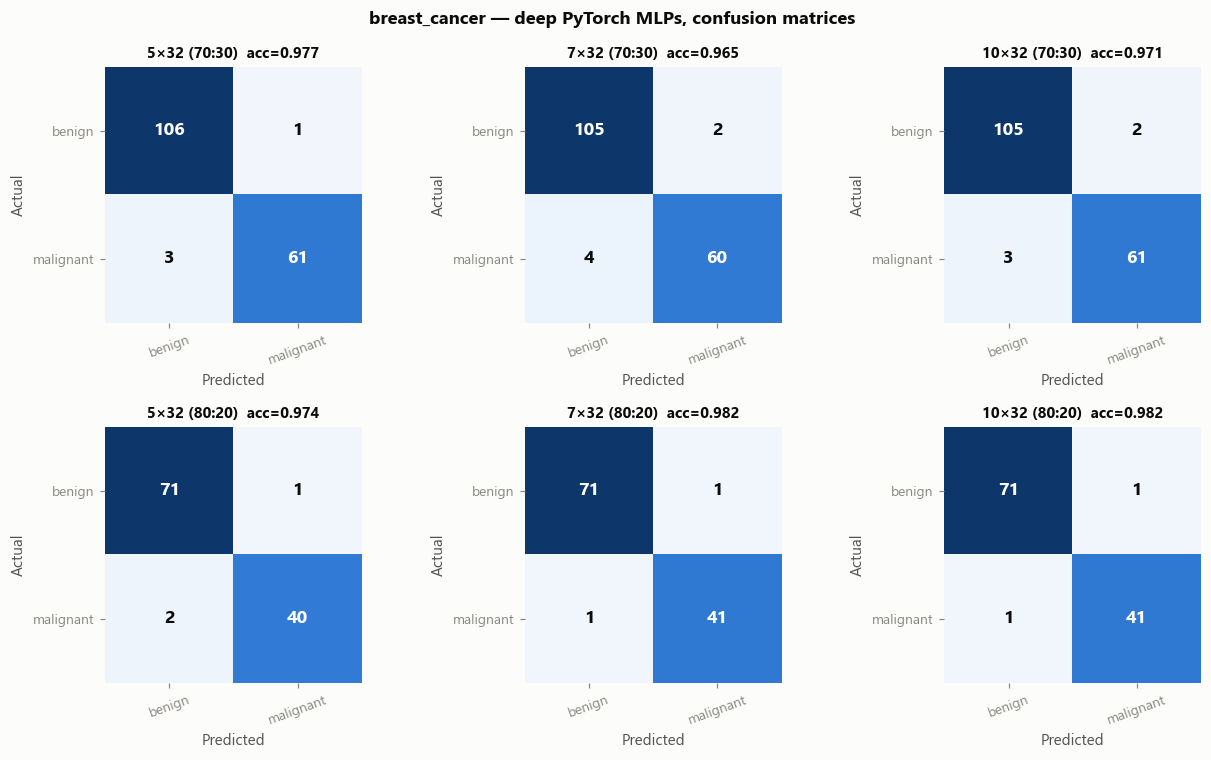

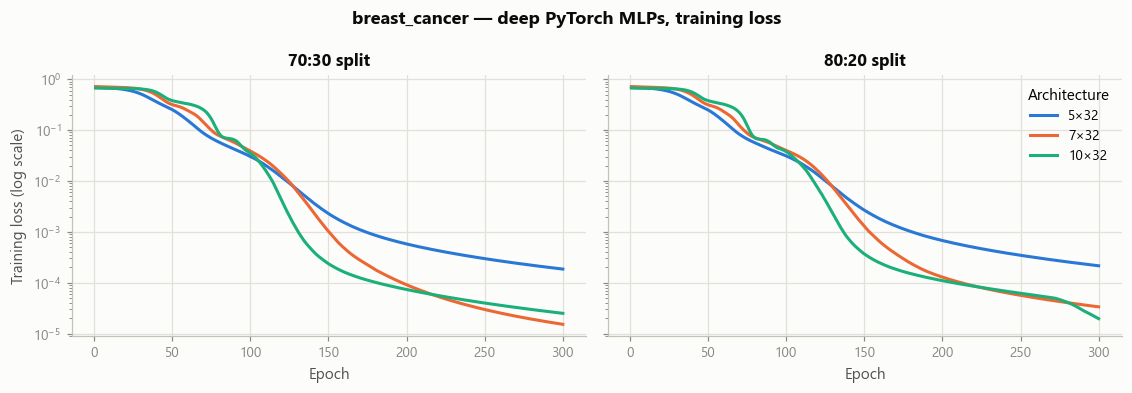

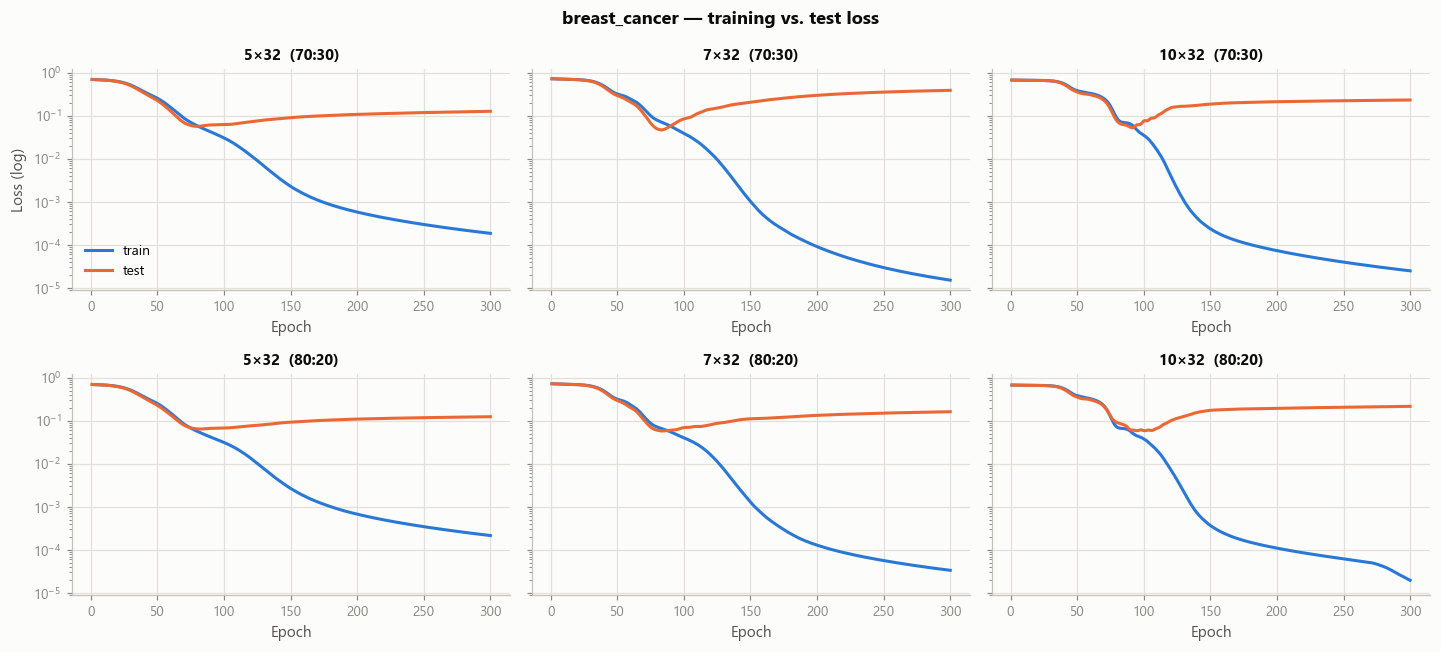

In [4]:
for ds, rs in torch_results.items():
    H.plot_confusion_matrices(rs, DATASETS[ds][3], f"{ds} — deep PyTorch MLPs, confusion matrices",
                              save=f"{OUT_DIR}/{ds}_torch_confusion.png"); plt.show()
    H.plot_loss_by_split(as_helper_results(rs), f"{ds} — deep PyTorch MLPs, training loss",
                         save=f"{OUT_DIR}/{ds}_torch_loss.png"); plt.show()
    H.plot_train_test_loss(as_helper_results(rs), f"{ds} — training vs. test loss",
                           save=f"{OUT_DIR}/{ds}_torch_train_test.png"); plt.show()

## 4. Discussion

**Deep networks fit the training data perfectly.** The 5-, 7- and 10-hidden-layer networks (4,500–10,500
parameters) reach a training loss of 1e-4 or lower and 100 % training accuracy within 300 epochs.

**Depth does not improve test accuracy.** Iris: 91–97 %; breast cancer: 96.5–98.3 %. That is the same range
as the one-hidden-layer networks from Q1/Q2 (Iris 91–97 %, breast cancer 97–99 %). The training-vs-test
loss curves show why: the test loss reaches its minimum after ≈75–110 epochs and then rises while the
training loss keeps falling. The networks memorise the 105–455 training samples.

**Conclusion.** A library makes very deep networks easy to build. On small tabular problems like Iris and
Breast Cancer, however, a single hidden layer is the appropriate model: extra depth adds thousands of
parameters without improving generalisation.